# Zajęcia 3: Agenci

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/adrianstando/2026Z-PJATK-TEG/blob/main/03-agenci/notebook.ipynb)

Zakres:
1. Tool calling: jak model prosi o wywołanie funkcji.
2. Pętla ReAct napisana ręcznie i rosnący kontekst.
3. Łańcuchy w LangChain, ta sama pętla jako graf w LangGraph, potem gotowe `create_agent`.
4. Pamięć krótkoterminowa (checkpointer, wątki) i długoterminowa (store).
5. Agentic RAG: agent sam decyduje, kiedy i czego szukać.
6. Wyszukiwanie w sieci z DuckDuckGo.

Przykłady korzystają z małej bazy wiedzy fikcyjnej firmy Nordwind (`data/nordwind.json`: delegacje, urlopy, sprzęt IT itd.).

Komórki z tagiem `web:*` są pokazywane na prezentacji.

## 0. Instalacja i konfiguracja

In [1]:
# Colab / Deepnote / Codespaces: odkomentuj i uruchom raz
# %pip install -q openai python-dotenv numpy tiktoken langchain langchain-openai langgraph ddgs

Konfiguracja dostawcy jest taka sama jak na zajęciach 1: zmienna `LLM_PROVIDER` w pliku `.env` albo w Colabie w *Secrets* ([00-dostep-do-llm](../00-dostep-do-llm/README.md)). Embeddingi do wyszukiwania w bazie wiedzy liczy `EMBED_PROVIDER` (domyślnie lokalna Ollama z `embeddinggemma`).

Agent wymaga modelu, który obsługuje tool calling. Wszystkie modele z tabeli w notebooku 01 to potrafią, ale małe modele lokalne (`gemma3:1b`) często mylą argumenty albo wywołują narzędzia bez potrzeby.

In [2]:
import os

try:  # Colab: sekrety z panelu "Secrets"
    from google.colab import userdata
    for k in ["LLM_PROVIDER", "EMBED_PROVIDER", "OLLAMA_CHAT", "OPENAI_API_KEY", "AZURE_OPENAI_ENDPOINT",
              "AZURE_OPENAI_API_KEY", "DEEPSEEK_API_KEY"]:
        try:
            os.environ.setdefault(k, userdata.get(k))
        except Exception:
            pass
except ImportError:  # lokalnie: plik .env
    from dotenv import load_dotenv
    load_dotenv(override=True)

from openai import OpenAI, AzureOpenAI

MODELS = {
    "openai":   {"chat": "gpt-5-nano", "agent": "gpt-5.4-nano", "embed": "text-embedding-3-small"},
    "azure":    {"chat": "gpt-4o-mini", "agent": "gpt-4o-mini", "embed": "text-embedding-3-small"},
    "deepseek": {"chat": "deepseek-chat", "agent": "deepseek-chat", "embed": None},
    "ollama":   {"chat": os.getenv("OLLAMA_CHAT", "gemma4:e4b"), "agent": "gemma4:e4b", "embed": "embeddinggemma"},
    "proxy":    {"chat": "copilot/gpt-5-mini", "agent": "copilot/gpt-5-mini", "embed": None},
}

def make_client(provider):
    if provider == "azure":
        return AzureOpenAI(api_version="2024-12-01-preview")
    if provider == "deepseek":
        return OpenAI(base_url="https://api.deepseek.com", api_key=os.environ["DEEPSEEK_API_KEY"])
    if provider == "ollama":
        return OpenAI(base_url="http://localhost:11434/v1", api_key="ollama")
    if provider == "proxy":
        return OpenAI(base_url="http://localhost:8787/v1", api_key="teg")
    return OpenAI()

PROVIDER = os.getenv("LLM_PROVIDER", "ollama")
EMBED_PROVIDER = os.getenv("EMBED_PROVIDER") or (PROVIDER if MODELS[PROVIDER]["embed"] else "ollama")

client = make_client(PROVIDER)
embed_client = client if EMBED_PROVIDER == PROVIDER else make_client(EMBED_PROVIDER)
CHAT, AGENT = MODELS[PROVIDER]["chat"], MODELS[PROVIDER]["agent"]  # AGENT: model do pętli agenta
EMBED = MODELS[EMBED_PROVIDER]["embed"]
print(f"czat: {PROVIDER} ({CHAT}, agent: {AGENT}) | embeddingi: {EMBED_PROVIDER} ({EMBED})")

czat: openai (gpt-5-nano, agent: gpt-5.4-nano) | embeddingi: ollama (embeddinggemma)


Agent wywołuje model kilka razy na jedno pytanie, więc liczy się czas i koszt pojedynczego wywołania. W przykładach pętlę napędza mały i szybki model (`AGENT`, w OpenAI `gpt-5.4-nano`). Każdy inny model z tool callingiem też działa: wystarczy zmienić `AGENT`.

### Baza wiedzy

Dziesięć krótkich dokumentów z zasadami fikcyjnej firmy. Każdy dokument to jeden fragment, więc nie trzeba go dzielić (chunking był na zajęciach 2). Wyszukiwanie jest wektorowe, jak w mini-wyszukiwarce z zajęć 1: embedding zapytania, cosinus z każdym dokumentem, `k` najlepszych.

In [3]:
import json, pathlib, urllib.request
import numpy as np

path = pathlib.Path("data/nordwind.json")
if path.exists():
    DOCS = json.loads(path.read_text(encoding="utf-8"))
else:  # Colab: plik z repozytorium
    url = "https://raw.githubusercontent.com/adrianstando/2026Z-PJATK-TEG/main/03-agenci/data/nordwind.json"
    DOCS = json.loads(urllib.request.urlopen(url).read())

def embed(texts):
    data = embed_client.embeddings.create(model=EMBED, input=texts).data
    V = np.array([d.embedding for d in data])
    return V / np.linalg.norm(V, axis=1, keepdims=True)

DOC_VECS = embed([f"{d['title']}. {d['text']}" for d in DOCS])

def retrieve(query, k=2):
    scores = DOC_VECS @ embed([query])[0]
    return [DOCS[i] for i in np.argsort(-scores)[:k]]

print(len(DOCS), "dokumentów:", ", ".join(d["id"] for d in DOCS))
print([d["id"] for d in retrieve("dieta w Niemczech")])

10 dokumentów: delegacje-krajowe, delegacje-zagraniczne, rozliczenie-delegacji, praca-zdalna, urlop, sprzet-it, szkolenia, bezpieczenstwo, benefity, kontakt
['delegacje-zagraniczne', 'delegacje-krajowe']


## 1. Tool calling: model nie wywołuje funkcji, tylko o nie prosi

Na zajęciach 1 agent liczył dni do Wigilii. Mechanizm jest ten sam w każdym API: do zapytania dołącza się listę narzędzi (`tools`), każde z nazwą, opisem i schematem argumentów w JSON Schema. Model może odpowiedzieć tekstem albo zwrócić **prośbę o wywołanie**: nazwę funkcji i argumenty jako tekst JSON. Funkcję uruchamia kod aplikacji, nie model.

Opis narzędzia jest częścią promptu: od niego zależy, czy model w ogóle sięgnie po narzędzie i z jakimi argumentami.

In [4]:
import ast, operator

def search_policy(query: str) -> str:
    """Zwraca 2 najbardziej pasujące fragmenty zasad firmy."""
    return "\n".join(f"[{d['id']}] {d['text']}" for d in retrieve(query))

OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv,
       ast.Pow: operator.pow, ast.USub: operator.neg}

def calculate(expression: str) -> str:
    """Bezpieczny kalkulator: tylko liczby i + - * / **, bez eval()."""
    def ev(node):
        if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
            return node.value
        if isinstance(node, ast.BinOp) and type(node.op) in OPS:
            return OPS[type(node.op)](ev(node.left), ev(node.right))
        if isinstance(node, ast.UnaryOp) and type(node.op) in OPS:
            return OPS[type(node.op)](ev(node.operand))
        raise ValueError(f"niedozwolone wyrażenie: {expression}")
    return str(round(ev(ast.parse(expression, mode="eval").body), 4))

TOOLS = {"search_policy": search_policy, "calculate": calculate}
TOOL_SPECS = [
    {"type": "function", "function": {
        "name": "search_policy",
        "description": "Wyszukuje w zasadach firmy Nordwind (delegacje, diety, urlopy, praca zdalna, sprzęt IT, szkolenia, benefity).",
        "parameters": {"type": "object", "properties": {"query": {"type": "string", "description": "Krótkie zapytanie, jeden temat."}},
                       "required": ["query"]}}},
    {"type": "function", "function": {
        "name": "calculate",
        "description": "Oblicza wyrażenie arytmetyczne, np. '2*150 + 3*49'.",
        "parameters": {"type": "object", "properties": {"expression": {"type": "string"}}, "required": ["expression"]}}},
]
print(calculate("2*150 + 3*49"))

447


In [5]:
resp = client.chat.completions.create(
    model=AGENT,
    messages=[{"role": "user", "content": "Ile wynosi dieta w delegacji do Niemiec?"}],
    tools=TOOL_SPECS,
)
choice = resp.choices[0]
call = choice.message.tool_calls[0]
print("finish_reason:", choice.finish_reason)
print("content:      ", choice.message.content)
print("id:           ", call.id)
print("name:         ", call.function.name)
print("arguments:    ", call.function.arguments, type(call.function.arguments).__name__)

# wykonanie po stronie aplikacji i odesłanie wyniku z tym samym id
result = TOOLS[call.function.name](**json.loads(call.function.arguments))
tool_msg = {"role": "tool", "tool_call_id": call.id, "content": result}
print("tool_msg:     ", json.dumps(tool_msg, ensure_ascii=False)[:150] + "…")

finish_reason: tool_calls
content:       None
id:            call_vmtCHXhwaYybQFUorL57l2z9
name:          search_policy
arguments:     {"query":"dieta delegacja Niemcy"} str
tool_msg:      {"role": "tool", "tool_call_id": "call_vmtCHXhwaYybQFUorL57l2z9", "content": "[delegacje-zagraniczne] Wniosek o delegację zagraniczną składa się w sys…


`finish_reason` to `tool_calls`, a `content` jest pusty: model nie odpowiedział, tylko poprosił o narzędzie. Argumenty przychodzą jako **tekst** JSON, który trzeba sparsować (`json.loads`) i sprawdzić; model może podać zły typ albo zmyśloną wartość. `id` łączy wynik narzędzia z prośbą: wiadomość `{"role": "tool", "tool_call_id": ...}` musi mieć to samo `id`.

> Starsze materiały i tutoriale używają parametrów `functions=` i `function_call=`. To API z 2023 roku, zastąpione przez `tools=`; nowe modele mogą go nie obsługiwać.

Gdy potrzebny jest sam JSON zgodny ze schematem, bez wywoływania funkcji, służą do tego *structured outputs*: [dokumentacja OpenAI](https://developers.openai.com/api/docs/guides/structured-outputs), [dokumentacja Anthropic](https://platform.claude.com/docs/en/build-with-claude/structured-outputs).

## 2. Pętla ReAct napisana ręcznie

ReAct (*Reason + Act*, Yao i in., 2022): model na przemian rozumuje i działa. Jeden krok pętli to:

1. **myśl** (*thinking*): model decyduje, co trzeba sprawdzić,
2. **akcja** (*action*): model prosi o wywołanie narzędzia,
3. **obserwacja** (*observation*): aplikacja wykonuje narzędzie, a wynik trafia do historii i wraca do modelu,

aż model uzna, że ma dość informacji, i odpowie tekstem. Modele rozumujące myślą w ukrytych tokenach; żeby myśl była widoczna, system prompt prosi o jedno zdanie przed każdym wywołaniem.

Funkcja `react()` to rozszerzona wersja `agent()` z zajęć 1: zapisuje dodatkowo dziennik kroków i liczbę tokenów wysłanych w każdym wywołaniu. Parametr `parallel_tool_calls=False` ogranicza model do jednego narzędzia na krok.

In [6]:
SYSTEM = ("Jesteś asystentem pracowników firmy Nordwind. Zasady firmy sprawdzasz narzędziem search_policy (po polsku, "
          "jedno zapytanie = jeden temat). Nie liczysz w pamięci: każdy rachunek wykonujesz narzędziem calculate. "
          "Przed każdym wywołaniem narzędzia piszesz jedno krótkie zdanie: co sprawdzasz i po co. Odpowiadasz krótko, po polsku, zwykłym tekstem, bez markdownu.")

def react(question, tools=TOOL_SPECS, max_steps=8, parallel=False, verbose=True):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    log = []
    for step in range(1, max_steps + 1):
        resp = client.chat.completions.create(model=AGENT, messages=messages, tools=tools, parallel_tool_calls=parallel)
        msg = resp.choices[0].message
        log.append({"sent": len(messages), "prompt_tokens": resp.usage.prompt_tokens})
        if verbose:
            print(f"[{step}] wysłano {len(messages)} wiadomości, {resp.usage.prompt_tokens} tokenów")
            if msg.content and msg.tool_calls:
                print(f"    myśl: {msg.content.strip()}")
        if not msg.tool_calls:
            messages.append({"role": "assistant", "content": msg.content})
            if verbose:
                print(f"    odpowiedź: {msg.content.strip()}")
            return messages, log
        messages.append(msg.model_dump(exclude_none=True))
        calls = [(c, json.loads(c.function.arguments or "{}")) for c in msg.tool_calls]
        if verbose:
            for call, args in calls:
                print(f"    akcja: {call.function.name}({json.dumps(args, ensure_ascii=False)})")
        for call, args in calls:
            result = TOOLS[call.function.name](**args)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
            if verbose:
                print(f"    obserwacja: {result[:90].replace(chr(10), ' ')}…" if len(result) > 90 else f"    obserwacja: {result}")
    return messages, log

messages, log = react("Jadę na 3 dni do Berlina, będą 2 noclegi. Ile maksymalnie mogę wydać na hotel i diety łącznie i do kiedy muszę rozliczyć delegację?")

[1] wysłano 2 wiadomości, 364 tokenów
    myśl: Sprawdzam w zasadach Nordwind, jakie są stawki diet (oraz zasady ich liczenia) dla delegacji zagranicznych.
    akcja: search_policy({"query": "stawki diet zagranicznych Niemcy Berlin delegacja ile i jak liczyć za 1 dobę"})
    obserwacja: [delegacje-zagraniczne] Wniosek o delegację zagraniczną składa się w systemie Podróże co n…


[2] wysłano 4 wiadomości, 671 tokenów
    myśl: Sprawdzam w zasadach Nordwind, do kiedy trzeba rozliczyć delegację po powrocie.
    akcja: search_policy({"query": "termin rozliczenia delegacji po powrocie do kiedy rozliczyć"})
    obserwacja: [rozliczenie-delegacji] Delegację rozlicza się w systemie Podróże w ciągu 14 dni od powrot…


[3] wysłano 6 wiadomości, 933 tokenów
    myśl: Liczyłem maksymalny limit na hotel i diety dla 2 noclegów i 3 dni w Niemczech (Berlin).
    akcja: calculate({"expression": "2*150 + 3*49"})
    obserwacja: 447


[4] wysłano 8 wiadomości, 1003 tokenów
    odpowiedź: W Berlinie (Niemcy) dieta wynosi 49 EUR za dzień, a limit hotelu/noclegu to 150 EUR za noc.

Dla 3 dni i 2 noclegów maksymalnie:
- hotel: 2 * 150 EUR = 300 EUR
- diety: 3 * 49 EUR = 147 EUR
Razem maksymalnie: 447 EUR

Rozliczenie delegacji musisz zrobić w systemie Podróże w ciągu 14 dni od powrotu.


Model sam rozbił pytanie na kroki: wyszukał zasady, wyliczył kwotę kalkulatorem i dopiero wtedy odpowiedział. Kod pętli nie zna kolejności kroków; zna tylko narzędzia. Kod wokół modelu (pętla, wykonanie narzędzi, historia, limit kroków) to **agent harness**; model tylko decyduje, co zrobić. `react()` to minimalny harness, a Claude Code czy Codex to harnessy rozbudowane (zajęcia 6).

### Ćwiczenie

Zadać pytanie wymagające dwóch różnych dokumentów (np. konferencja zagraniczna w Pradze: czyja zgoda i jaka dieta). Ile razy agent szuka? Co się dzieje przy `max_steps=1`?

### Kilka narzędzi w jednym kroku

Bez ograniczenia model może w jednej odpowiedzi poprosić o kilka narzędzi naraz (*parallel tool calls*). Aplikacja wykonuje wszystkie i odsyła wszystkie wyniki przed kolejnym wywołaniem modelu: mniej kroków, mniej razy wysłana historia. Mały model rzadko robi to sam, dlatego polecenie wprost o to prosi.

In [7]:
_ = react("Sprawdź naraz, w jednym kroku: ile wynosi dieta w Czechach, jak długie musi być hasło i ile kosztuje karta sportowa?", parallel=True)

[1] wysłano 2 wiadomości, 354 tokenów
    myśl: Sprawdzam w zasadach firmy: dietę w Czechach, wymagania dotyczące długości hasła oraz koszt karty sportowej.
    akcja: search_policy({"query": "dieta Czechy wysokość"})
    akcja: search_policy({"query": "długość hasła wymagania minimalna liczba znaków"})
    akcja: search_policy({"query": "koszt karta sportowa cena"})
    obserwacja: [delegacje-zagraniczne] Wniosek o delegację zagraniczną składa się w systemie Podróże co n…
    obserwacja: [bezpieczenstwo] Hasło do konta firmowego ma co najmniej 14 znaków. Logowanie do poczty i …
    obserwacja: [benefity] Firma finansuje prywatną opiekę medyczną dla pracownika. Karta sportowa kosztuj…


[2] wysłano 6 wiadomości, 1063 tokenów
    odpowiedź: Dieta w Czechach: 35 EUR za dzień.

Hasło (konto firmowe): co najmniej 14 znaków.

Karta sportowa: 60 zł miesięcznie (dopłaca firma).


## 3. Kontekst rośnie z każdym krokiem

API jest bezstanowe: każde wywołanie wysyła całą dotychczasową historię, łącznie z definicjami narzędzi i wynikami wyszukiwania. Koszt agenta to suma tokenów wejściowych **wszystkich** wywołań, a nie tylko ostatniego.

Komórka poniżej rozbija każde wywołanie z poprzedniego przykładu na części (liczone tokenizerem `o200k_base`; reszta do `prompt_tokens` z API to definicje narzędzi i narzut formatu).

In [8]:
import tiktoken
enc = tiktoken.get_encoding("o200k_base")

def tokens(m):
    text = m.get("content") or ""
    text += "".join(c["function"]["name"] + c["function"]["arguments"] for c in m.get("tool_calls", []))
    return len(enc.encode(text))

KIND = {"system": "system", "user": "pytanie", "assistant": "wywołania", "tool": "wyniki"}
print(f"{'wywołanie':>9} {'system':>7} {'pytanie':>8} {'wywołania':>10} {'wyniki':>7} {'narzędzia+narzut':>17} {'razem':>6}")
for i, entry in enumerate(log, 1):
    parts = {k: 0 for k in KIND.values()}
    for m in messages[:entry["sent"]]:
        parts[KIND[m["role"]]] += tokens(m)
    rest = entry["prompt_tokens"] - sum(parts.values())
    print(f"{i:>9} {parts['system']:>7} {parts['pytanie']:>8} {parts['wywołania']:>10} {parts['wyniki']:>7} {rest:>17} {entry['prompt_tokens']:>6}")
print(f"\nsuma tokenów wejściowych: {sum(e['prompt_tokens'] for e in log)}")

wywołanie  system  pytanie  wywołania  wyniki  narzędzia+narzut  razem
        1     113       45          0       0               206    364
        2     113       45         58     220               235    671
        3     113       45        101     410               264    933
        4     113       45        143     411               291   1003

suma tokenów wejściowych: 2971


Wyniki wyszukiwania są największą rosnącą częścią. W długich zadaniach (dziesiątki kroków) kontekst zapełnia się starymi obserwacjami. Typowe zabiegi: krótsze wyniki narzędzi, usuwanie starych wyników, streszczanie historii (w LangChain: `SummarizationMiddleware`, `ContextEditingMiddleware`).

## 4. Łańcuchy w LangChain

LangChain składa aplikację z gotowych klocków. Najprostsza forma to **łańcuch**: operator `|` łączy kroki, a wynik jednego staje się wejściem następnego. Krokiem może być wyszukiwanie w bazie (np. `vectorstore.as_retriever()` z Chroma z zajęć 2), szablon promptu, model, także z narzędziami (`llm.bind_tools(...)`) albo parser odpowiedzi. Historii rozmowy nie trzyma się już w łańcuchu: służy do tego checkpointer z sekcji 7.

Łańcuch ma stałą ścieżkę: kroki idą zawsze w tej samej kolejności i nie ma pętli. Do przepływu, w którym model decyduje, co dalej, służy graf (następna sekcja).

In [9]:
from langchain_openai import ChatOpenAI, AzureChatOpenAI

def make_llm(model):
    if PROVIDER == "azure":
        return AzureChatOpenAI(azure_deployment=model, api_version="2024-12-01-preview")
    return ChatOpenAI(model=model, base_url=str(client.base_url), api_key=client.api_key)

llm = make_llm(AGENT)

In [10]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda, RunnablePassthrough

def find_context(question):
    return "\n".join(f"[{d['id']}] {d['text']}" for d in retrieve(question))

prompt = ChatPromptTemplate.from_messages([
    ("system", "Odpowiadasz krótko, po polsku, zwykłym tekstem, na podstawie kontekstu.\n\n{context}"),
    ("human", "{question}"),
])

chain = (
    {"context": RunnableLambda(find_context), "question": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser()
)

print(chain.invoke("Do kiedy trzeba rozliczyć delegację?"))

Delegację trzeba rozliczyć w systemie **Podróże w ciągu 14 dni od powrotu**.


## 5. Ta sama pętla jako graf w LangGraph

LangGraph opisuje przepływ jako graf: **stan** (dowolna struktura zdefiniowana w kodzie; tu wystarcza lista wiadomości, czyli `MessagesState`), **węzły** (funkcje, które zwracają zmianę stanu) i **krawędzie** (co dalej). Pętla ReAct to dwa węzły:

- `model`: wywołanie LLM z historią,
- `tools`: wykonanie narzędzi, o które poprosił model,

i krawędź warunkowa `tools_condition`: jeśli ostatnia wiadomość zawiera `tool_calls`, przejście do `tools`, w przeciwnym razie koniec. Z `tools` zawsze wraca się do `model`.

Narzędzia w LangChain to zwykłe funkcje z dekoratorem `@tool`: nazwa, opis (docstring) i schemat argumentów (z typów) powstają automatycznie.

In [11]:
from langchain.tools import tool

@tool
def search_policy_tool(query: str) -> str:
    """Wyszukuje w zasadach firmy Nordwind (delegacje, diety, urlopy, praca zdalna, sprzęt IT, szkolenia, benefity).
    Jedno zapytanie = jeden temat."""
    return search_policy(query)

@tool
def calculate_tool(expression: str) -> str:
    """Oblicza wyrażenie arytmetyczne, np. '2*150 + 3*49'."""
    return calculate(expression)

search_policy_tool.name, calculate_tool.name = "search_policy", "calculate"
LC_TOOLS = [search_policy_tool, calculate_tool]
print(json.dumps(search_policy_tool.args, ensure_ascii=False))

{"query": {"title": "Query", "type": "string"}}


In [12]:
from langchain_core.messages import SystemMessage
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.prebuilt import ToolNode, tools_condition

llm_with_tools = llm.bind_tools(LC_TOOLS, parallel_tool_calls=False)

def call_model(state: MessagesState):
    reply = llm_with_tools.invoke([SystemMessage(SYSTEM)] + state["messages"])
    return {"messages": [reply]}            # stan: dopisanie odpowiedzi do listy

builder = StateGraph(MessagesState)
builder.add_node("model", call_model)
builder.add_node("tools", ToolNode(LC_TOOLS))
builder.add_edge(START, "model")
builder.add_conditional_edges("model", tools_condition)   # tool_calls? -> "tools" : END
builder.add_edge("tools", "model")
graph = builder.compile()

print(graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools --> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



`draw_mermaid()` zwraca opis grafu w składni [Mermaid](https://mermaid.live), a `draw_mermaid_png()` rysuje go jako obrazek (wymaga dostępu do sieci). Tak samo można szybko obejrzeć większy graf, np. system wieloagentowy.

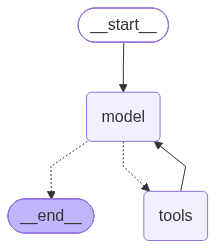

In [13]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

`stream(..., stream_mode="updates")` zwraca kolejne kroki: który węzeł się wykonał i co dopisał do stanu.

In [14]:
question = "Jadę na 3 dni do Berlina, będą 2 noclegi. Ile maksymalnie mogę wydać na hotel i diety łącznie i do kiedy muszę rozliczyć delegację?"
for update in graph.stream({"messages": [("user", question)]}, stream_mode="updates"):
    for node, change in update.items():
        for m in change["messages"]:
            if m.type == "ai" and m.tool_calls:
                what = ", ".join(f"{c['name']}({json.dumps(c['args'], ensure_ascii=False)})" for c in m.tool_calls)
            else:
                what = m.content.strip().replace("\n", " ")[:110]
            print(f"{node:>5} -> {what}")

model -> search_policy({"query": "delegacja Berlin 3 dni 2 noclegi limit diety stawki hotel rozliczenie do kiedy"})
tools -> [delegacje-krajowe] Podróż służbową w kraju zatwierdza bezpośredni przełożony. Dieta za każdy pełny dzień dele


model -> search_policy({"query": "termin rozliczenia delegacji zagranicznej do kiedy Nordwind"})
tools -> [rozliczenie-delegacji] Delegację rozlicza się w systemie Podróże w ciągu 14 dni od powrotu. Do rozliczenia do


model -> calculate({"expression": "2*150 + 3*49"})
tools -> 447


model -> Dla Berlina (delegacja zagraniczna, Niemcy) masz: 1) Hotel: limit 150 EUR za noc. Przy 2 noclegach maksymalnie


## 6. `create_agent`: gotowa pętla

Graf z poprzedniej sekcji to tak częsty wzorzec, że LangChain ma go w jednej funkcji: `create_agent`. Wystarczy podać model (instancję LLM), narzędzia i system prompt, a powstaje agent do wielokrotnego użycia. Wynik to skompilowany graf LangGraph (`CompiledStateGraph`) z węzłami `model` i `tools`, więc działa na nim `stream`, checkpointer i reszta. Dodatkowe zachowania (limit wywołań, streszczanie historii, zatwierdzanie przez człowieka) dokłada się jako *middleware*.

In [15]:
from langchain.agents import create_agent

agent = create_agent(llm, LC_TOOLS, system_prompt=SYSTEM)

result = agent.invoke({"messages": [("user", "Ile dni wcześniej trzeba złożyć wniosek o delegację do Pragi?")]})
for m in result["messages"]:
    text = m.content if m.content else ", ".join(f"{c['name']}({c['args']})" for c in m.tool_calls)
    print(f"{m.type:>6}: {text.strip()[:110]}")
print("\nwęzły grafu:", [n for n in agent.get_graph().nodes])

 human: Ile dni wcześniej trzeba złożyć wniosek o delegację do Pragi?
    ai: Sprawdzam w zasadach Nordwind, ile dni wcześniej trzeba złożyć wniosek o delegację do Pragi.
  tool: [delegacje-zagraniczne] Wniosek o delegację zagraniczną składa się w systemie Podróże co najmniej 7 dni przed 
    ai: Wniosek o delegację do Pragi (delegację zagraniczną) trzeba złożyć w systemie Podróże co najmniej 7 dni przed 

węzły grafu: ['__start__', 'model', 'tools', '__end__']


## 7. Pamięć krótkoterminowa: checkpointer i wątki

Agent z poprzedniej komórki niczego nie pamięta między wywołaniami `invoke`. **Checkpointer** automatycznie zapisuje stan grafu (tu: historię wiadomości) po każdym kroku pod identyfikatorem wątku (`thread_id`). Kolejne wywołanie z tym samym `thread_id` zaczyna od zapisanej historii; inny `thread_id` to nowa rozmowa.

`InMemorySaver` trzyma stan w pamięci procesu. W aplikacji używa się trwałego zapisu w bazie (`langgraph-checkpoint-sqlite`, `langgraph-checkpoint-postgres`).

In [16]:
from langgraph.checkpoint.memory import InMemorySaver

agent = create_agent(llm, LC_TOOLS, system_prompt=SYSTEM, checkpointer=InMemorySaver())

def ask(text, thread):
    out = agent.invoke({"messages": [("user", text)]}, {"configurable": {"thread_id": thread}})
    text = " ".join(out["messages"][-1].content.split())
    return text if len(text) < 160 else text[:160] + "…"

print("[t1]", ask("Cześć, jestem Ola. Pracuję w Gdańsku.", "t1"))
print("[t1]", ask("W jakim mieście pracuję?", "t1"))
print("[t2]", ask("W jakim mieście pracuję?", "t2"))
state = agent.get_state({"configurable": {"thread_id": "t1"}})
print(f"\nwątek 't1': {len(state.values['messages'])} wiadomości w zapisanym stanie")

[t1] Cześć Ola! Miło mi. W czym mogę pomóc w ramach zasad Nordwind? Jeśli powiesz, czego dotyczy sprawa (np. delegacja, dieta, urlop, praca zdalna, sprzęt IT, szkole…


[t1] Pracujesz w Gdańsku.


[t2] W dostępnych zasadach Nordwind nie ma informacji, jaką dokładnie lokalizację (miasto) przypisuje się pracownikowi. Jeśli chodzi o miejsce pracy, zasady dotyczą …

wątek 't1': 4 wiadomości w zapisanym stanie


W wątku `t1` agent pamięta, w jakim mieście pracuje Ola. Nowy wątek `t2` tej informacji nie ma. Pamięć krótkoterminowa to po prostu historia wiadomości, więc rośnie jak kontekst z sekcji 3.

## 8. Pamięć długoterminowa: store

Fakty, które mają przetrwać między wątkami (preferencje, dane użytkownika), zapisuje się osobno w **store**: magazynie klucz–wartość z przestrzeniami nazw, np. `("fakty", user_id)`. Tutaj agent dostaje narzędzia do zapisu i odczytu, a narzędzie sięga do store przez `ToolRuntime`. `user_id` przekazuje się w `context`, a nie w treści rozmowy, żeby model nie mógł go podmienić.

In [17]:
from dataclasses import dataclass
from langchain.tools import ToolRuntime
from langgraph.store.memory import InMemoryStore

@dataclass
class Context:
    user_id: str

@tool
def remember(fact: str, runtime: ToolRuntime[Context]) -> str:
    """Zapisuje trwały fakt o użytkowniku (preferencje, stałe informacje)."""
    ns = ("fakty", runtime.context.user_id)
    runtime.store.put(ns, str(len(runtime.store.search(ns))), {"fact": fact})
    return "zapisano"

@tool
def recall(runtime: ToolRuntime[Context]) -> str:
    """Zwraca zapisane fakty o użytkowniku."""
    items = runtime.store.search(("fakty", runtime.context.user_id))
    return "\n".join(i.value["fact"] for i in items) or "brak zapisanych faktów"

store = InMemoryStore()
agent = create_agent(llm, LC_TOOLS + [remember, recall], context_schema=Context, store=store,
                     checkpointer=InMemorySaver(),
                     system_prompt=SYSTEM + " Gdy użytkownik podaje informację o sobie (imię, miasto, preferencje), od razu zapisujesz ją narzędziem remember. "
                                            "Gdy pytanie dotyczy użytkownika, najpierw wywołujesz recall.")

def ask(text, thread, user):
    out = agent.invoke({"messages": [("user", text)]}, {"configurable": {"thread_id": thread}}, context=Context(user))
    return " ".join(out["messages"][-1].content.split())

print("[t1]", ask("Cześć, jestem Ola. Pracuję w Gdańsku.", "t1", "ola"))
print("[t2]", ask("W jakim mieście pracuję?", "t2", "ola"))
print("\nstore:", [i.value for i in store.search(("fakty", "ola"))])

[t1] Cześć Ola! Miło Cię poznać. W czym mogę pomóc w sprawach Nordwind?


[t2] Pracujesz w Gdańsku.

store: [{'fact': 'Użytkowniczka ma na imię Ola i pracuje w Gdańsku.'}]


Wątek `t2` nie widzi historii wątku `t1`, ale agent odczytał fakt ze store. Harness może budować taką pamięć na kilka sposobów: narzędziami jak tutaj, automatycznie w tle albo wsadowo, analizując zakończone rozmowy. Pamięć może też mieć postać grafu (grafy wiedzy na zajęciach 4). `InMemoryStore` wspiera wyszukiwanie semantyczne po embeddingach (parametr `index`), co przy wielu wspomnieniach działa jak mały RAG nad pamięcią.

## 9. Agentic RAG: agent decyduje, kiedy szukać

Klasyczny RAG (zajęcia 2) ma stały przepływ: **zawsze** jedno wyszukiwanie na pytanie użytkownika, potem odpowiedź. Agentic RAG daje wyszukiwanie modelowi jako narzędzie, więc model:

- nie szuka, gdy pytanie tego nie wymaga,
- przeformułowuje zapytanie (krótsze, w języku dokumentów),
- szuka kilka razy, gdy pytanie łączy kilka tematów.

Porównanie na trzech pytaniach: rachunek bez związku z bazą, pytanie z jednego dokumentu i pytanie o dwa różne tematy.

In [18]:
def classic_rag(question):
    docs = retrieve(question)              # zawsze dokładnie jedno wyszukiwanie, zapytanie = pytanie
    context = "\n".join(f"[{d['id']}] {d['text']}" for d in docs)
    answer = client.chat.completions.create(model=AGENT, messages=[
        {"role": "system", "content": "Odpowiadasz krótko, po polsku, zwykłym tekstem, na podstawie kontekstu."},
        {"role": "user", "content": f"Kontekst:\n{context}\n\nPytanie: {question}"},
    ]).choices[0].message.content
    return [d["id"] for d in docs], answer

def agent_searches(messages):
    results = {m["tool_call_id"]: m["content"] for m in messages if m["role"] == "tool"}
    calls = [c for m in messages if m["role"] == "assistant" for c in m.get("tool_calls", [])]
    return [(json.loads(c["function"]["arguments"])["query"],
             [line[1:].split("]")[0] for line in results[c["id"]].split("\n") if line.startswith("[")])
            for c in calls if c["function"]["name"] == "search_policy"]

QUESTIONS = [
    "Ile to 17 * 23?",
    "Do kiedy trzeba rozliczyć delegację?",
    "Jadę w delegację do Czech. Ile wynosi dieta w delegacji i jak długie musi być hasło?",
]
for q in QUESTIONS:
    docs, answer = classic_rag(q)
    print(f"PYTANIE: {q}")
    print("  RAG: 1 wyszukiwanie")
    print(f"    retrieve({q!r}) -> {', '.join(docs)}")
    print(f"    odpowiedź: {' '.join(answer.split())}")
    messages, _ = react(q, verbose=False)
    searches = agent_searches(messages)
    print(f"  agentic RAG: liczba wyszukiwań {len(searches)}")
    for query, found in searches:
        print(f"    search_policy({query!r}) -> {', '.join(found)}")
    print(f"    odpowiedź: {' '.join(messages[-1]['content'].split())}\n")

PYTANIE: Ile to 17 * 23?
  RAG: 1 wyszukiwanie
    retrieve('Ile to 17 * 23?') -> urlop, bezpieczenstwo
    odpowiedź: 17 × 23 = 391.


  agentic RAG: liczba wyszukiwań 0
    odpowiedź: 17 * 23 = 391.



PYTANIE: Do kiedy trzeba rozliczyć delegację?
  RAG: 1 wyszukiwanie
    retrieve('Do kiedy trzeba rozliczyć delegację?') -> rozliczenie-delegacji, delegacje-krajowe
    odpowiedź: Delegację trzeba rozliczyć w systemie **Podróże w ciągu 14 dni od powrotu**.


  agentic RAG: liczba wyszukiwań 1
    search_policy('do kiedy rozliczyć delegację') -> rozliczenie-delegacji, delegacje-krajowe
    odpowiedź: Delegację trzeba rozliczyć w systemie „Podróże” w ciągu 14 dni od powrotu. Do rozliczenia dołącza się skany paragonów i faktur.



PYTANIE: Jadę w delegację do Czech. Ile wynosi dieta w delegacji i jak długie musi być hasło?
  RAG: 1 wyszukiwanie
    retrieve('Jadę w delegację do Czech. Ile wynosi dieta w delegacji i jak długie musi być hasło?') -> delegacje-zagraniczne, delegacje-krajowe
    odpowiedź: Dla delegacji do Czech dieta wynosi **35 EUR za dzień**. Hasło musi mieć **co najmniej 7 dni** wyprzedzenia w systemie Podróże (czyli wniosek składa się **min. 7 dni przed wyjazdem**).


  agentic RAG: liczba wyszukiwań 2
    search_policy('dieta delegacja Czech') -> delegacje-zagraniczne, delegacje-krajowe
    search_policy('hasło długość hasła Nordwind') -> bezpieczenstwo, kontakt
    odpowiedź: Dieta w delegacji do Czech wynosi 35 EUR za dzień. Hasło do konta firmowego musi mieć co najmniej 14 znaków.



Przy pytaniu o dwa tematy agent rozbija je na osobne zapytania, po jednym na temat, i dostaje dokumenty do obu części. Klasyczny RAG szuka jednym zapytaniem, więc wynik zależy od tego, który temat przeważy w całym pytaniu. Przy prostym rachunku agent w ogóle nie sięga do bazy.

Każde wyszukiwanie to kolejne wywołanie modelu, czyli więcej tokenów i dłuższy czas odpowiedzi. Jasna instrukcja w system prompcie pomaga ustalić, kiedy model ma szukać.

### Ćwiczenie

Dodać do bazy dokument, który przeczy innemu (np. nowa stawka diety w Niemczech od 2027 roku), i sprawdzić, czy agent zauważy konflikt.

## 10. Wyszukiwanie w sieci z DuckDuckGo

Narzędziem może być dowolna funkcja, także wyszukiwarka internetowa. Biblioteka `ddgs` wywołuje DuckDuckGo, z limitami zapytań. Wyniki zmieniają się z dnia na dzień, więc zapisany wynik jest tylko przykładem.

In [19]:
from ddgs import DDGS

@tool
def web_search(query: str) -> str:
    """Wyszukuje w internecie. Zwraca tytuły, adresy i krótkie opisy 4 wyników."""
    try:
        hits = DDGS().text(query, max_results=4)
    except Exception as e:  # limit zapytań, brak sieci
        return f"błąd wyszukiwania: {e}"
    return "\n".join(f"- {h['title']} ({h['href']}): {h['body'][:200]}" for h in hits)

web_agent = create_agent(llm, [web_search], system_prompt="Odpowiadasz krótko, po polsku, podając źródło (adres).")
result = web_agent.invoke({"messages": [("user", "Kiedy wyszła wersja 1.0 biblioteki LangGraph?")]})
for m in result["messages"]:
    if m.type == "ai" and m.tool_calls:
        print("szukanie:", [c["args"]["query"] for c in m.tool_calls])
print(result["messages"][-1].content.strip())

szukanie: ['LangGraph 1.0 release date']
Wersja **LangGraph 1.0** została ogłoszona w dniu **3 czerwca 2024 r.** (wraz z premierą LangChain 1.0). Źródło: https://www.langchain.com/blog/langchain-langgraph-1dot0


Treść stron trafia do kontekstu modelu jako obserwacja. Strona może zawierać instrukcje dla modelu (*prompt injection*), np. „zignoruj poprzednie polecenia”. Wyniki narzędzi traktuje się jako dane, nie polecenia; agent z dostępem do sieci nie powinien mieć jednocześnie narzędzi, które coś wysyłają lub usuwają, bez zatwierdzenia przez człowieka (`HumanInTheLoopMiddleware`).

## 11. Podsumowanie

- Tool calling: model zwraca nazwę narzędzia i argumenty w JSON; kod wykonuje narzędzie i odsyła wynik z tym samym `tool_call_id`.
- ReAct = pętla myśl → akcja → obserwacja, dopóki model nie odpowie tekstem. Ręcznie to kilkanaście linii.
- Łańcuch w LangChain to stała sekwencja kroków; LangGraph zapisuje pętlę jako graf (`model` ⇄ `tools`), a `create_agent` buduje go w jednej linii.
- Każdy krok wysyła całą historię: koszt rośnie z liczbą kroków.
- Pamięć krótkoterminowa = checkpointer + `thread_id`; długoterminowa = store z przestrzeniami nazw.
- Agentic RAG: wyszukiwanie jako narzędzie; agent decyduje, czy, czego i ile razy szukać.

Zadanie po zajęciach: [`zadanie.ipynb`](zadanie.ipynb), własny agent kodujący w LangGraph. Na następnych zajęciach (4): grafy wiedzy i GraphRAG. Na zajęciach 5: MCP, czyli standard udostępniania narzędzi agentom, i systemy wieloagentowe.